# 模块三：相关性分析

### 🎯 分析目的

探究各评分维度间的内在关联，**识别杠杆维度**——即改善哪个维度，对整体通过率提升最大。

### 📋 分析内容

1. 评分维度描述性统计
2. 7 个评分维度的相关性矩阵
3. 杠杆维度识别（与通过率最相关的维度）
4. 根因 × 评分维度关联分析
5. 难度 × 评分维度交互效应
6. 分支 × 评分维度差异分析
7. 关键维度对散点分析
8. 关键发现总结

### 📂 输入文件

| 文件 | 说明 |
|------|------|
| `analysis_output/module1_cleaned_data.csv` | 505 条完整评测数据 |
| `analysis_output/module2_failure_attribution.csv` | 43 条带根因标签的失败用例 |

### 📂 输出文件

| 文件 | 说明 |
|------|------|
| `analysis_output/module3_correlation_matrix.csv` | 维度相关性矩阵 |
| `analysis_output/module3_leverage_dimensions.csv` | 杠杆维度分析 |
| `analysis_output/module3_rootcause_dimension.csv` | 根因 × 维度交叉 |
| `analysis_output/module3_branch_dimension.csv` | 分支 × 维度交叉 |
| `analysis_output/module3_difficulty_dimension.csv` | 难度 × 维度交叉 |
| `charts/10_correlation_heatmap.png` | 相关性热力图 |
| `charts/11_leverage_dimensions.png` | 杠杆维度柱状图 |
| `charts/12_rootcause_dimension_heatmap.png` | 根因 × 维度热力图 |
| `charts/13_difficulty_dimension_heatmap.png` | 难度 × 维度热力图 |
| `charts/14_branch_dimension_heatmap.png` | 分支 × 维度热力图 |
| `charts/15_dimension_scatter.png` | 关键维度对散点图 |

## 3.1 环境配置与数据加载

In [1]:
# ========== 环境配置 ==========
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from scipy import stats

# 中文字体配置（Windows）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
matplotlib.rcParams['axes.unicode_minus'] = False
matplotlib.rcParams['figure.dpi'] = 120
matplotlib.rcParams['savefig.dpi'] = 200
matplotlib.rcParams['savefig.bbox'] = 'tight'

# 路径自适应：如果在 notebooks/ 子目录下，切到项目根目录
HERE = os.getcwd()
if os.path.basename(HERE) == 'notebooks':
    os.chdir('..')
print(f'✅ 工作目录: {os.getcwd()}')

os.makedirs('charts', exist_ok=True)
os.makedirs('analysis_output', exist_ok=True)

# ========== 加载完整数据 ==========
df = pd.read_csv('analysis_output/module1_cleaned_data.csv', encoding='utf-8-sig')
print(f'✅ 加载完整数据: {len(df)} 条')

# ========== 加载失败用例（带根因标签）==========
df_failed = pd.read_csv('analysis_output/module2_failure_attribution.csv', encoding='utf-8-sig')
print(f'✅ 加载失败用例: {len(df_failed)} 条（带根因标签）')

# ========== 字段自适应：适配 score.xxx 和 xxx 两种格式 ==========
def pick(*cands):
    """从候选列名中选第一个存在于 df 中的"""
    for c in cands:
        if c in df.columns:
            return c
    return None

INTENT    = pick('score.intent_accuracy', 'intent_accuracy')
BRANCH    = pick('score.branch_routing', 'branch_routing')
RELEVANCE = pick('score.answer_relevance', 'answer_relevance')
COMPLETE  = pick('score.information_completeness', 'information_completeness')
FAITH     = pick('score.faithfulness', 'faithfulness')
TONE      = pick('score.tone_compliance', 'tone_compliance')
BOUNDARY  = pick('score.boundary_correctness', 'boundary_correctness')

SCORE_COLS = [c for c in [INTENT, BRANCH, RELEVANCE, COMPLETE, FAITH, TONE, BOUNDARY] if c]

SCORE_NAMES_CN = {}
if INTENT:    SCORE_NAMES_CN[INTENT]    = '意图准确率'
if BRANCH:    SCORE_NAMES_CN[BRANCH]    = '分支路由'
if RELEVANCE: SCORE_NAMES_CN[RELEVANCE] = '答案相关性'
if COMPLETE:  SCORE_NAMES_CN[COMPLETE]  = '信息完整性'
if FAITH:     SCORE_NAMES_CN[FAITH]     = '忠实度'
if TONE:      SCORE_NAMES_CN[TONE]      = '语气合规'
if BOUNDARY:  SCORE_NAMES_CN[BOUNDARY]  = '边界正确性'

# 数值化
for col in SCORE_COLS:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print(f'\n✅ 评分维度（{len(SCORE_COLS)} 个）:')
for c in SCORE_COLS:
    print(f'   {c:35s} → {SCORE_NAMES_CN[c]}')


✅ 工作目录: C:\Users\Darren\Desktop\ecommerce_rag_eval
✅ 加载完整数据: 505 条
✅ 加载失败用例: 43 条（带根因标签）

✅ 评分维度（7 个）:
   intent_accuracy                     → 意图准确率
   branch_routing                      → 分支路由
   answer_relevance                    → 答案相关性
   information_completeness            → 信息完整性
   faithfulness                        → 忠实度
   tone_compliance                     → 语气合规
   boundary_correctness                → 边界正确性


## 3.2 评分维度描述性统计

对各评分维度做均值、标准差、分位数统计，定位**最弱维度**和**最不稳定维度**。

In [3]:
# ========== 评分维度描述性统计 ==========
# 中文感知宽度工具
def dw(s):
    """显示宽度：中文=2，英文/数字=1"""
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    if align == 'right':
        return ' ' * gap + s
    return s + ' ' * gap

desc = df[SCORE_COLS].describe().T
desc['维度'] = desc.index.map(lambda x: SCORE_NAMES_CN.get(x, x))
desc = desc[['维度', 'count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

# 计算每列显示宽度
col_w = {}
for c in desc.columns:
    header_w = dw(c)
    if c == '维度':
        data_w = max(desc[c].astype(str).map(dw).max(), header_w)
    elif c == 'count':
        data_w = max(len(str(int(v))) for v in desc[c].values)
    else:
        data_w = max(len(f'{v:.2f}') for v in desc[c].values)
    col_w[c] = max(header_w, data_w) + 2

# 打印
print('┌─ 3.2 评分维度描述性统计 ' + '─' * 36 + '┐')
print('│ 均值/标准差/分位数统计，定位最弱 & 最不稳定维度')
print('└' + '─' * 70 + '┘')

header = '│ ' + '│ '.join(pad(c, col_w[c], 'right') for c in desc.columns) + ' │'
sep = '├─' + '─┼─'.join('─' * (col_w[c] - 1) for c in desc.columns) + '─┤'
top = '┌─' + '─┬─'.join('─' * (col_w[c] - 1) for c in desc.columns) + '─┐'
bot = '└─' + '─┴─'.join('─' * (col_w[c] - 1) for c in desc.columns) + '─┘'

print(top)
print(header)
print(sep)
for _, row in desc.iterrows():
    cells = []
    for c in desc.columns:
        if c == '维度':
            cells.append(pad(row[c], col_w[c]))
        elif c == 'count':
            cells.append(pad(f"{int(row[c])}", col_w[c], 'right'))
        else:
            cells.append(pad(f"{row[c]:.2f}", col_w[c], 'right'))
    print('│ ' + '│ '.join(cells) + ' │')
print(bot)

# 解读
print(f'\n📌 均值最高: {desc.loc[desc["mean"].idxmax(), "维度"]} ({desc["mean"].max():.2f}) → 系统最强维度')
print(f'📌 均值最低: {desc.loc[desc["mean"].idxmin(), "维度"]} ({desc["mean"].min():.2f}) → 系统最弱维度')
print(f'📌 波动最大: {desc.loc[desc["std"].idxmax(), "维度"]} ({desc["std"].max():.2f}) → 最不稳定维度')
print(f'📌 波动最小: {desc.loc[desc["std"].idxmin(), "维度"]} ({desc["std"].min():.2f}) → 最稳定维度')


┌─ 3.2 评分维度描述性统计 ────────────────────────────────────┐
│ 均值/标准差/分位数统计，定位最弱 & 最不稳定维度
└──────────────────────────────────────────────────────────────────────┘
┌─────────────┬────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┐
│         维度│   count│   mean│    std│    min│    25%│    50%│    75%│    max │
├─────────────┼────────┼───────┼───────┼───────┼───────┼───────┼───────┼───────┤
│ 意图准确率  │     505│   4.81│   0.77│   0.00│   5.00│   5.00│   5.00│   5.00 │
│ 分支路由    │     505│   4.70│   1.03│   0.00│   5.00│   5.00│   5.00│   5.00 │
│ 答案相关性  │     505│   4.70│   0.94│   0.00│   5.00│   5.00│   5.00│   5.00 │
│ 信息完整性  │     505│   4.32│   1.28│   0.00│   4.00│   5.00│   5.00│   5.00 │
│ 忠实度      │     505│   4.85│   0.64│   0.00│   5.00│   5.00│   5.00│   5.00 │
│ 语气合规    │     505│   4.93│   0.38│   0.00│   5.00│   5.00│   5.00│   5.00 │
│ 边界正确性  │     505│   4.82│   0.67│   0.00│   5.00│   5.00│   5.00│   5.00 │
└─────────────┴────────┴───────┴───────┴───────┴───────┴──

## 3.3 评分维度相关性矩阵

计算 7 个评分维度间的 Pearson 相关系数，识别**高度联动的维度对**。

In [4]:
# ========== 7 维度相关性矩阵 ==========
print('┌─ 3.3 评分维度相关性矩阵 (Pearson) ' + '─' * 24 + '┐')
print('│ 计算 7 个评分维度间的 Pearson 相关系数')
print('└' + '─' * 70 + '┘')

corr_matrix = df[SCORE_COLS].corr()

# 中文标签
labels_cn = [SCORE_NAMES_CN[c] for c in SCORE_COLS]
corr_display = corr_matrix.copy()
corr_display.index = labels_cn
corr_display.columns = labels_cn

# 中文对齐打印
def dw(s):
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    if align == 'right':
        return ' ' * gap + s
    return s + ' ' * gap

# 计算列宽
n = len(labels_cn)
cell_w = max(max(dw(l) for l in labels_cn), 8) + 2

# 表头
header = '│ ' + pad('', 10) + '│' + '│'.join(pad(l, cell_w, 'right') for l in labels_cn) + '│'
sep = '├─' + '─┼─'.join(['─' * 9] + ['─' * (cell_w - 1)] * n) + '─┤'
top = '┌─' + '─┬─'.join(['─' * 9] + ['─' * (cell_w - 1)] * n) + '─┐'
bot = '└─' + '─┴─'.join(['─' * 9] + ['─' * (cell_w - 1)] * n) + '─┘'

print(top)
print(header)
print(sep)
for i, row_label in enumerate(labels_cn):
    row_vals = corr_display.iloc[i]
    cells = [pad(row_label, 10)] + [pad(f'{v:.3f}', cell_w, 'right') for v in row_vals]
    print('│ ' + '│'.join(cells) + '│')
print(bot)

# 最强相关对
print(f'\n--- 最强相关性 TOP 5 ---')
corr_pairs = []
for i in range(n):
    for j in range(i + 1, n):
        n1 = labels_cn[i]
        n2 = labels_cn[j]
        r = corr_matrix.iloc[i, j]
        corr_pairs.append((n1, n2, r))

corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for i, (n1, n2, r) in enumerate(corr_pairs[:5], 1):
    if abs(r) >= 0.5:
        strength = '强'
    elif abs(r) >= 0.3:
        strength = '中'
    else:
        strength = '弱'
    direction = '正相关' if r > 0 else '负相关'
    print(f'  {i}. {n1} ↔ {n2}: r = {r:.3f} ({strength}{direction})')


┌─ 3.3 评分维度相关性矩阵 (Pearson) ────────────────────────┐
│ 计算 7 个评分维度间的 Pearson 相关系数
└──────────────────────────────────────────────────────────────────────┘
┌───────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┬─────────────┐
│           │  意图准确率│    分支路由│  答案相关性│  信息完整性│      忠实度│    语气合规│  边界正确性│
├───────────┼─────────────┼─────────────┼─────────────┼─────────────┼─────────────┼─────────────┼─────────────┤
│ 意图准确率│       1.000│       0.896│       0.902│       0.697│       0.638│       0.515│       0.500│
│ 分支路由  │       0.896│       1.000│       0.933│       0.742│       0.659│       0.544│       0.528│
│ 答案相关性│       0.902│       0.933│       1.000│       0.831│       0.651│       0.536│       0.517│
│ 信息完整性│       0.697│       0.742│       0.831│       1.000│       0.551│       0.419│       0.533│
│ 忠实度    │       0.638│       0.659│       0.651│       0.551│       1.000│       0.504│       0.572│
│ 语气合规  │       0.515│       0.544│       0.5

## 3.4 可视化：相关性热力图

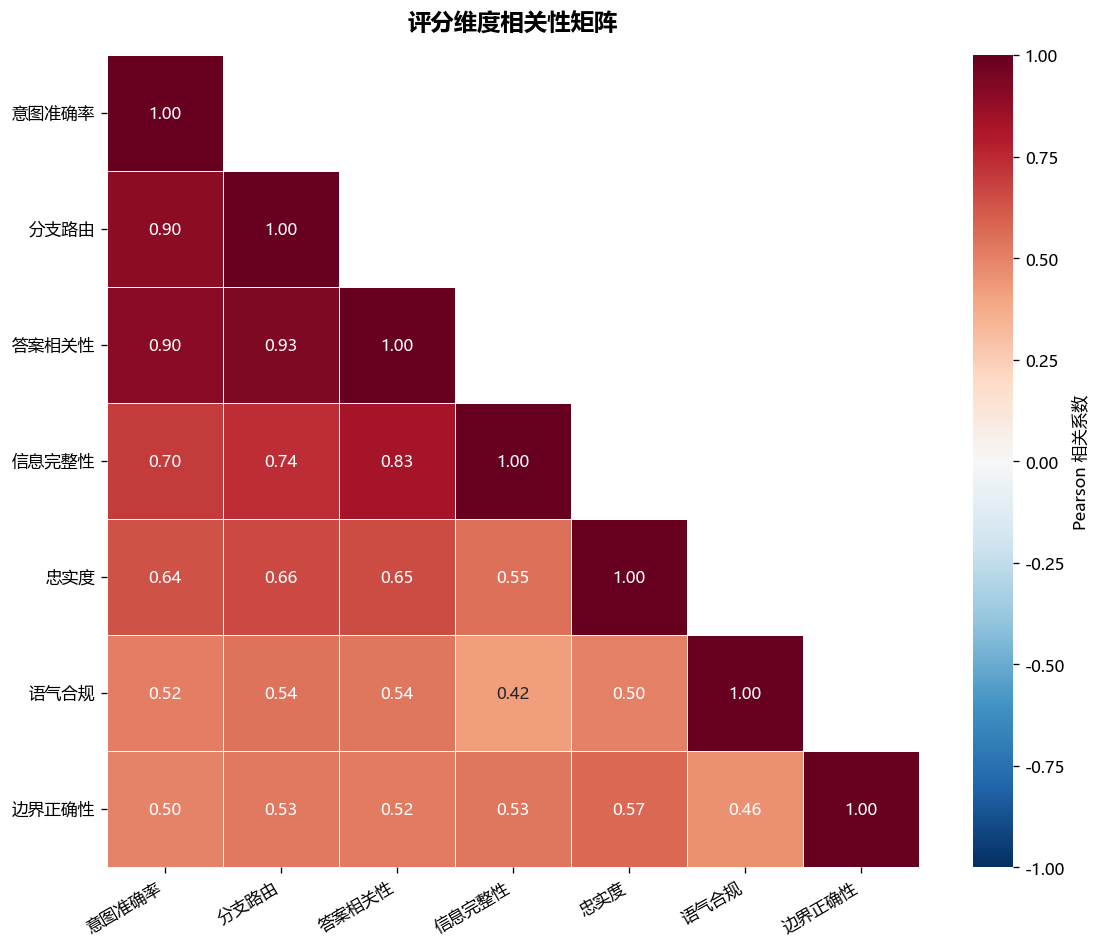

💾 已保存: charts/10_correlation_heatmap.png


In [5]:
# ========== 图1：评分维度相关性热力图 ==========
fig, ax = plt.subplots(figsize=(10, 8))

labels_cn = [SCORE_NAMES_CN[c] for c in SCORE_COLS]
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            xticklabels=labels_cn, yticklabels=labels_cn, ax=ax,
            cbar_kws={'label': 'Pearson 相关系数'})

ax.set_title('评分维度相关性矩阵', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('charts/10_correlation_heatmap.png')
plt.show()
print('💾 已保存: charts/10_correlation_heatmap.png')


## 3.5 杠杆维度识别

> **杠杆维度定义**：与整体通过率（所有维度 ≥ 4）**点二列相关**最高的维度。
> 改善杠杆维度，对整体通过率提升效果最大。

In [6]:
# ========== 杠杆维度识别 ==========
print('┌─ 3.5 杠杆维度识别 ' + '─' * 48 + '┐')
print('│ 点二列相关：连续评分维度 vs 二值通过/失败标签')
print('└' + '─' * 70 + '┘')

# 定义整体通过（宽松口径：所有维度 >= 4）
df['all_pass'] = df[SCORE_COLS].ge(4).all(axis=1)
print(f'\n📊 整体通过率(宽松): {df["all_pass"].sum()}/{len(df)} = {df["all_pass"].sum()/len(df)*100:.1f}%')

# 计算每个维度与整体通过率的点二列相关
leverage = []
for col in SCORE_COLS:
    r, p = stats.pointbiserialr(df[col], df['all_pass'])
    leverage.append({
        'dimension': col,
        'dimension_cn': SCORE_NAMES_CN[col],
        'correlation': r,
        'p_value': p,
        'mean_pass': df[df['all_pass']][col].mean(),
        'mean_fail': df[~df['all_pass']][col].mean(),
        'gap': df[df['all_pass']][col].mean() - df[~df['all_pass']][col].mean(),
    })

lev_df = pd.DataFrame(leverage).sort_values('correlation', ascending=False)

# 打印
print(f'\n{"─" * 78}')
print(f'{"维度":8s}  {"r":>8s}   {"p":>10s}   {"通过组均值":>10s}   {"失败组均值":>10s}   {"gap":>6s}  可视化')
print(f'{"─" * 78}')
for _, row in lev_df.iterrows():
    if row['p_value'] < 0.001:
        sig = '***'
    elif row['p_value'] < 0.01:
        sig = '**'
    elif row['p_value'] < 0.05:
        sig = '*'
    else:
        sig = 'ns'
    bar = '█' * int(abs(row['correlation']) * 40)
    print(f'{row["dimension_cn"]:8s}  {row["correlation"]:>8.3f}  {sig:>10s}  {row["mean_pass"]:>10.2f}  {row["mean_fail"]:>10.2f}  {row["gap"]:>6.2f}  {bar}')

top_lev = lev_df.iloc[0]
print(f'\n→ 杠杆维度: {top_lev["dimension_cn"]} (r = {top_lev["correlation"]:.3f}, p = {top_lev["p_value"]:.2e})')
print(f'  通过组均值 {top_lev["mean_pass"]:.2f} vs 失败组均值 {top_lev["mean_fail"]:.2f}')
print(f'  差距 {top_lev["gap"]:.2f} 分 → 改善该维度对整体通过率提升最大')


┌─ 3.5 杠杆维度识别 ────────────────────────────────────────────────┐
│ 点二列相关：连续评分维度 vs 二值通过/失败标签
└──────────────────────────────────────────────────────────────────────┘

📊 整体通过率(宽松): 427/505 = 84.6%

──────────────────────────────────────────────────────────────────────────────
维度               r            p        通过组均值        失败组均值      gap  可视化
──────────────────────────────────────────────────────────────────────────────
信息完整性        0.859         ***        4.79        1.76    3.04  ██████████████████████████████████
答案相关性        0.747         ***        5.00        3.06    1.93  █████████████████████████████
分支路由         0.686         ***        5.00        3.05    1.95  ███████████████████████████
意图准确率        0.574         ***        5.00        3.78    1.22  ██████████████████████
忠实度          0.499         ***        4.99        4.10    0.89  ███████████████████
边界正确性        0.417         ***        4.94        4.17    0.77  ████████████████
语气合规         0.403         ***       

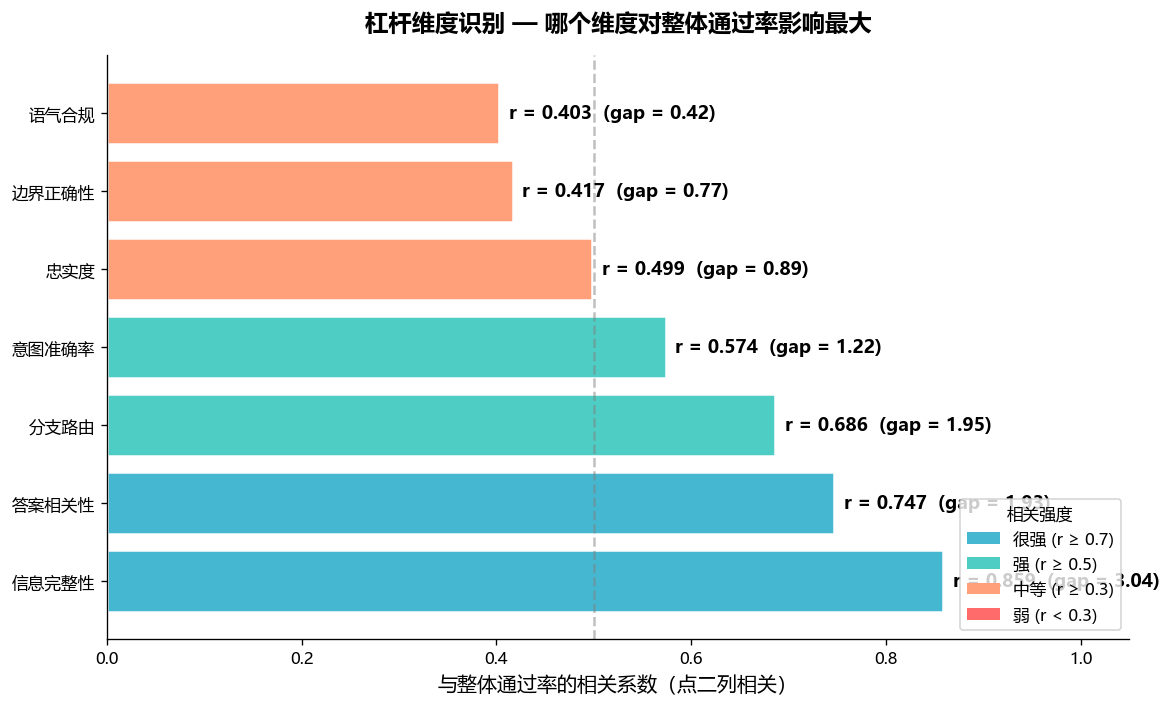

💾 已保存: charts/11_leverage_dimensions.png


In [7]:
# ========== 图2：杠杆维度柱状图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

colors = []
for r in lev_df['correlation']:
    if r >= 0.7:
        colors.append('#45B7D1')
    elif r >= 0.5:
        colors.append('#4ECDC4')
    elif r >= 0.3:
        colors.append('#FFA07A')
    else:
        colors.append('#FF6B6B')

bars = ax.barh(lev_df['dimension_cn'], lev_df['correlation'], color=colors,
               edgecolor='white', linewidth=1.5)

for bar, r, gap in zip(bars, lev_df['correlation'], lev_df['gap']):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
            f'r = {r:.3f}  (gap = {gap:.2f})',
            ha='left', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('与整体通过率的相关系数（点二列相关）', fontsize=12)
ax.set_title('杠杆维度识别 — 哪个维度对整体通过率影响最大',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlim(0, 1.05)
ax.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5, label='强相关阈值 (0.5)')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#45B7D1', label='很强 (r ≥ 0.7)'),
    Patch(facecolor='#4ECDC4', label='强 (r ≥ 0.5)'),
    Patch(facecolor='#FFA07A', label='中等 (r ≥ 0.3)'),
    Patch(facecolor='#FF6B6B', label='弱 (r < 0.3)'),
]
ax.legend(handles=legend_elements, loc='lower right', title='相关强度')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('charts/11_leverage_dimensions.png')
plt.show()
print('💾 已保存: charts/11_leverage_dimensions.png')


## 3.6 根因 × 评分维度关联分析

按模块二的根因标签分组，观察各根因样本的维度得分特征。

In [8]:
# ========== 根因与评分维度的关联 ==========
print('┌─ 3.6 根因 × 评分维度 关联分析 ' + '─' * 30 + '┐')
print('│ 按根因分组，看各维度得分均值')
print('└' + '─' * 70 + '┘')

# 失败用例按根因分组
rc_dim = df_failed.groupby('root_cause_name')[SCORE_COLS].mean().round(2)
rc_dim.columns = [SCORE_NAMES_CN.get(c, c) for c in rc_dim.columns]

# 中文对齐打印
def dw(s):
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    if align == 'right':
        return ' ' * gap + s
    return s + ' ' * gap

dim_cols = list(rc_dim.columns)
name_w = max(rc_dim.index.map(dw).max(), dw('根因')) + 2
col_w = {}
for c in dim_cols:
    header_w = dw(c)
    data_w = max(len(f'{v:.2f}') for v in rc_dim[c].values)
    col_w[c] = max(header_w, data_w) + 2

header = '│ ' + pad('根因', name_w) + '│' + '│'.join(pad(c, col_w[c], 'right') for c in dim_cols) + '│'
sep = '├─' + '─┼─'.join(['─' * (name_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┤'
top = '┌─' + '─┬─'.join(['─' * (name_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┐'
bot = '└─' + '─┴─'.join(['─' * (name_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┘'

print(top)
print(header)
print(sep)
for idx in rc_dim.index:
    cells = [pad(idx, name_w)] + [pad(f'{rc_dim.loc[idx, c]:.2f}', col_w[c], 'right') for c in dim_cols]
    print('│ ' + '│'.join(cells) + '│')
print(bot)

print(f'\n--- 解读：每个根因的最弱维度 ---')
for rc in rc_dim.index:
    weakest_dim = rc_dim.loc[rc].idxmin()
    weakest_val = rc_dim.loc[rc].min()
    print(f'  {rc:14s} → 最弱维度: {weakest_dim} ({weakest_val:.2f})')


┌─ 3.6 根因 × 评分维度 关联分析 ──────────────────────────────┐
│ 按根因分组，看各维度得分均值
└──────────────────────────────────────────────────────────────────────┘
┌──────────────────┬─────────────┬───────────┬─────────────┬─────────────┬─────────┬───────────┬─────────────┐
│ 根因             │  意图准确率│  分支路由│  答案相关性│  信息完整性│  忠实度│  语气合规│  边界正确性│
├──────────────────┼─────────────┼───────────┼─────────────┼─────────────┼─────────┼───────────┼─────────────┤
│ LLM生成缺陷      │        4.00│      3.00│        3.83│        1.83│    4.83│      5.00│        4.50│
│ 其他/需人工复核  │        4.00│      3.00│        3.75│        3.25│    4.75│      5.00│        4.50│
│ 分类器误路由     │        2.26│      0.90│        1.39│        0.84│    3.26│      4.10│        3.45│
│ 幻觉             │        5.00│      3.00│        4.00│        4.00│    3.50│      5.00│        4.50│
└──────────────────┴─────────────┴───────────┴─────────────┴─────────────┴─────────┴───────────┴─────────────┘

--- 解读：每个根因的最弱维度 ---
  LLM生成缺陷        → 最弱维度: 信息完整性 (1

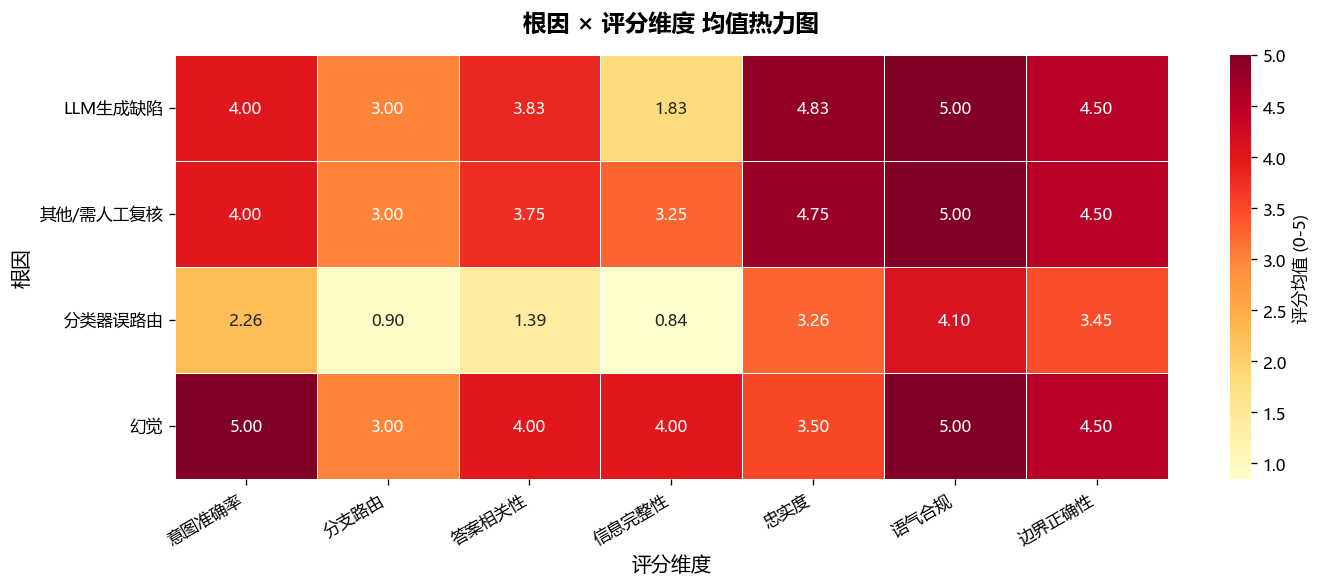

💾 已保存: charts/12_rootcause_dimension_heatmap.png


In [9]:
# ========== 图3：根因 × 评分维度 热力图 ==========
fig, ax = plt.subplots(figsize=(12, 5))

sns.heatmap(rc_dim, annot=True, fmt='.2f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, cbar_kws={'label': '评分均值 (0-5)'})

ax.set_title('根因 × 评分维度 均值热力图', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('评分维度', fontsize=12)
ax.set_ylabel('根因', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('charts/12_rootcause_dimension_heatmap.png')
plt.show()
print('💾 已保存: charts/12_rootcause_dimension_heatmap.png')


## 3.7 难度 × 评分维度交互效应

分析"简单 / 中等 / 困难"三个难度等级下，各维度的均值变化。

In [10]:
# ========== 难度 × 评分维度 交互分析 ==========
print('┌─ 3.7 难度 × 评分维度 交互分析 ' + '─' * 30 + '┐')
print('│ 分析简单/中等/困难下各维度均值变化')
print('└' + '─' * 70 + '┘')

diff_dim = df.groupby('difficulty')[SCORE_COLS].mean().round(2)
diff_dim.columns = [SCORE_NAMES_CN.get(c, c) for c in diff_dim.columns]

# 按难度排序
diff_order = ['简单', '中等', '困难']
diff_dim = diff_dim.reindex([d for d in diff_order if d in diff_dim.index])

# 中文对齐打印
def dw(s):
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    if align == 'right':
        return ' ' * gap + s
    return s + ' ' * gap

dim_cols = list(diff_dim.columns)
diff_w = max(diff_dim.index.map(dw).max(), dw('难度')) + 2
col_w = {}
for c in dim_cols:
    header_w = dw(c)
    data_w = max(len(f'{v:.2f}') for v in diff_dim[c].values)
    col_w[c] = max(header_w, data_w) + 2

header = '│ ' + pad('难度', diff_w) + '│' + '│'.join(pad(c, col_w[c], 'right') for c in dim_cols) + '│'
sep = '├─' + '─┼─'.join(['─' * (diff_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┤'
top = '┌─' + '─┬─'.join(['─' * (diff_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┐'
bot = '└─' + '─┴─'.join(['─' * (diff_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┘'

print(top)
print(header)
print(sep)
for idx in diff_dim.index:
    cells = [pad(idx, diff_w)] + [pad(f'{diff_dim.loc[idx, c]:.2f}', col_w[c], 'right') for c in dim_cols]
    print('│ ' + '│'.join(cells) + '│')
print(bot)

print(f'\n--- 解读：每个维度随难度的变化 ---')
for dim in diff_dim.columns:
    if '简单' in diff_dim.index and '困难' in diff_dim.index:
        simple_v = diff_dim.loc['简单', dim]
        hard_v = diff_dim.loc['困难', dim]
        delta = hard_v - simple_v
        direction = '↑' if delta > 0 else '↓'
        print(f'  {dim:8s}: 简单 = {simple_v:.2f} → 困难 = {hard_v:.2f} ({direction}{abs(delta):.2f})')


┌─ 3.7 难度 × 评分维度 交互分析 ──────────────────────────────┐
│ 分析简单/中等/困难下各维度均值变化
└──────────────────────────────────────────────────────────────────────┘
┌───────┬─────────────┬───────────┬─────────────┬─────────────┬─────────┬───────────┬─────────────┐
│ 难度  │  意图准确率│  分支路由│  答案相关性│  信息完整性│  忠实度│  语气合规│  边界正确性│
├───────┼─────────────┼───────────┼─────────────┼─────────────┼─────────┼───────────┼─────────────┤
│ 简单  │        4.93│      4.91│        4.87│        4.49│    4.97│      4.99│        4.88│
│ 中等  │        4.70│      4.50│        4.51│        4.08│    4.74│      4.85│        4.75│
│ 困难  │        4.80│      4.67│        4.71│        4.41│    4.83│      4.96│        4.83│
└───────┴─────────────┴───────────┴─────────────┴─────────────┴─────────┴───────────┴─────────────┘

--- 解读：每个维度随难度的变化 ---
  意图准确率   : 简单 = 4.93 → 困难 = 4.80 (↓0.13)
  分支路由    : 简单 = 4.91 → 困难 = 4.67 (↓0.24)
  答案相关性   : 简单 = 4.87 → 困难 = 4.71 (↓0.16)
  信息完整性   : 简单 = 4.49 → 困难 = 4.41 (↓0.08)
  忠实度     : 简单 = 4.97 → 困难 =

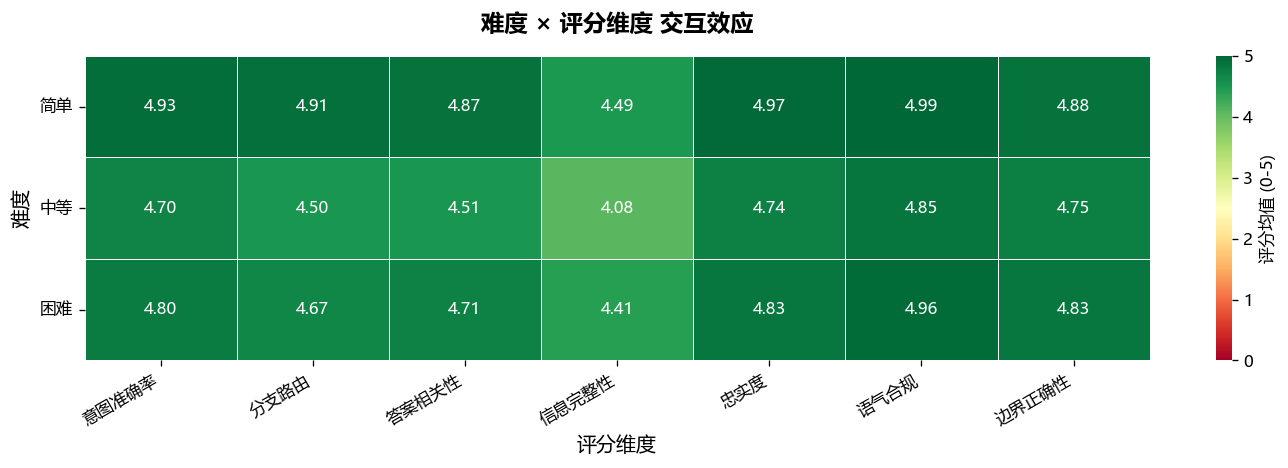

💾 已保存: charts/13_difficulty_dimension_heatmap.png


In [11]:
# ========== 图4：难度 × 评分维度 热力图 ==========
fig, ax = plt.subplots(figsize=(12, 4))

sns.heatmap(diff_dim, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax,
            linewidths=0.5, cbar_kws={'label': '评分均值 (0-5)'}, vmin=0, vmax=5)

ax.set_title('难度 × 评分维度 交互效应', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('评分维度', fontsize=12)
ax.set_ylabel('难度', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('charts/13_difficulty_dimension_heatmap.png')
plt.show()
print('💾 已保存: charts/13_difficulty_dimension_heatmap.png')


## 3.8 分支 × 评分维度差异分析

按业务分支（商品咨询 / 订单查询 / 退款换货 / 投诉 / 其他 / 边界混淆）分组，定位**各分支的最弱维度**。

In [12]:
# ========== 分支 × 评分维度差异 ==========
print('┌─ 3.8 分支 × 评分维度 差异分析 ' + '─' * 30 + '┐')
print('│ 按业务分支分组，定位各分支的最弱维度')
print('└' + '─' * 70 + '┘')

branch_dim = df.groupby('category')[SCORE_COLS].mean().round(2)
branch_dim.columns = [SCORE_NAMES_CN.get(c, c) for c in branch_dim.columns]

# 按整体均分排序
branch_dim['_overall'] = branch_dim.mean(axis=1)
branch_dim = branch_dim.sort_values('_overall', ascending=False)
branch_display = branch_dim.drop(columns=['_overall'])

# 中文对齐打印
def dw(s):
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    if align == 'right':
        return ' ' * gap + s
    return s + ' ' * gap

dim_cols = list(branch_display.columns)
branch_w = max(branch_display.index.map(dw).max(), dw('分支')) + 2
col_w = {}
for c in dim_cols:
    header_w = dw(c)
    data_w = max(len(f'{v:.2f}') for v in branch_display[c].values)
    col_w[c] = max(header_w, data_w) + 2

header = '│ ' + pad('分支', branch_w) + '│' + '│'.join(pad(c, col_w[c], 'right') for c in dim_cols) + '│'
sep = '├─' + '─┼─'.join(['─' * (branch_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┤'
top = '┌─' + '─┬─'.join(['─' * (branch_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┐'
bot = '└─' + '─┴─'.join(['─' * (branch_w - 1)] + ['─' * (col_w[c] - 1) for c in dim_cols]) + '─┘'

print(top)
print(header)
print(sep)
for idx in branch_display.index:
    cells = [pad(idx, branch_w)] + [pad(f'{branch_display.loc[idx, c]:.2f}', col_w[c], 'right') for c in dim_cols]
    print('│ ' + '│'.join(cells) + '│')
print(bot)

print(f'\n--- 各分支最弱 & 最强维度 ---')
for branch in branch_display.index:
    weakest = branch_display.loc[branch].idxmin()
    weakest_v = branch_display.loc[branch].min()
    strongest = branch_display.loc[branch].idxmax()
    strongest_v = branch_display.loc[branch].max()
    print(f'  {branch:8s}: 最弱 = {weakest}({weakest_v:.2f})  最强 = {strongest}({strongest_v:.2f})')


┌─ 3.8 分支 × 评分维度 差异分析 ──────────────────────────────┐
│ 按业务分支分组，定位各分支的最弱维度
└──────────────────────────────────────────────────────────────────────┘
┌───────────┬─────────────┬───────────┬─────────────┬─────────────┬─────────┬───────────┬─────────────┐
│ 分支      │  意图准确率│  分支路由│  答案相关性│  信息完整性│  忠实度│  语气合规│  边界正确性│
├───────────┼─────────────┼───────────┼─────────────┼─────────────┼─────────┼───────────┼─────────────┤
│ 订单查询  │        5.00│      5.00│        5.00│        4.39│    5.00│      5.00│        4.53│
│ 商品咨询  │        4.89│      4.83│        4.77│        4.33│    4.91│      4.97│        4.87│
│ 其他      │        4.71│      4.69│        4.65│        4.61│    4.76│      4.78│        4.86│
│ 退款换货  │        4.67│      4.56│        4.63│        4.44│    4.86│      4.97│        4.87│
│ 投诉      │        4.62│      4.23│        4.36│        4.04│    4.60│      4.79│        4.68│
│ 边界混淆  │        4.59│      3.95│        4.27│        3.73│    4.68│      4.91│        4.77│
└───────────┴─────

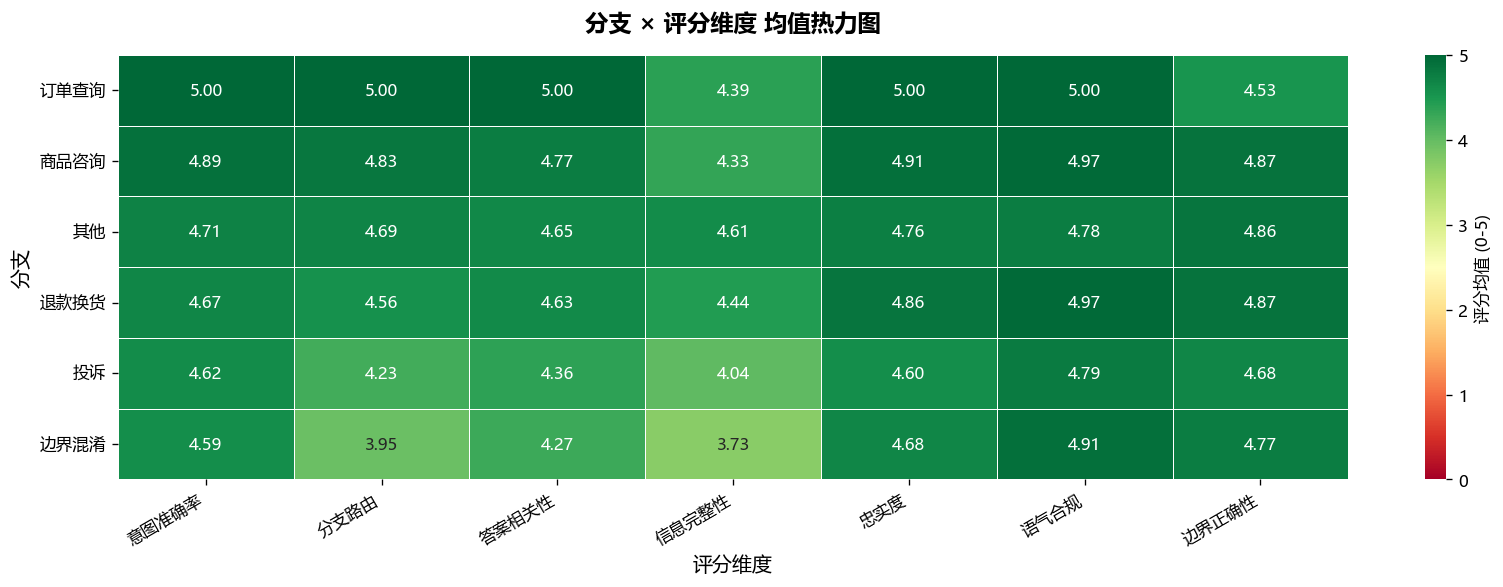

💾 已保存: charts/14_branch_dimension_heatmap.png


In [13]:
# ========== 图5：分支 × 评分维度 热力图 ==========
fig, ax = plt.subplots(figsize=(14, 5))

sns.heatmap(branch_display, annot=True, fmt='.2f', cmap='RdYlGn', ax=ax,
            linewidths=0.5, cbar_kws={'label': '评分均值 (0-5)'}, vmin=0, vmax=5)

ax.set_title('分支 × 评分维度 均值热力图', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('评分维度', fontsize=12)
ax.set_ylabel('分支', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('charts/14_branch_dimension_heatmap.png')
plt.show()
print('💾 已保存: charts/14_branch_dimension_heatmap.png')


## 3.9 关键维度对散点分析

选取相关性最强的 2 对维度，用散点图直观展示**通过 vs 失败**的样本分布差异。

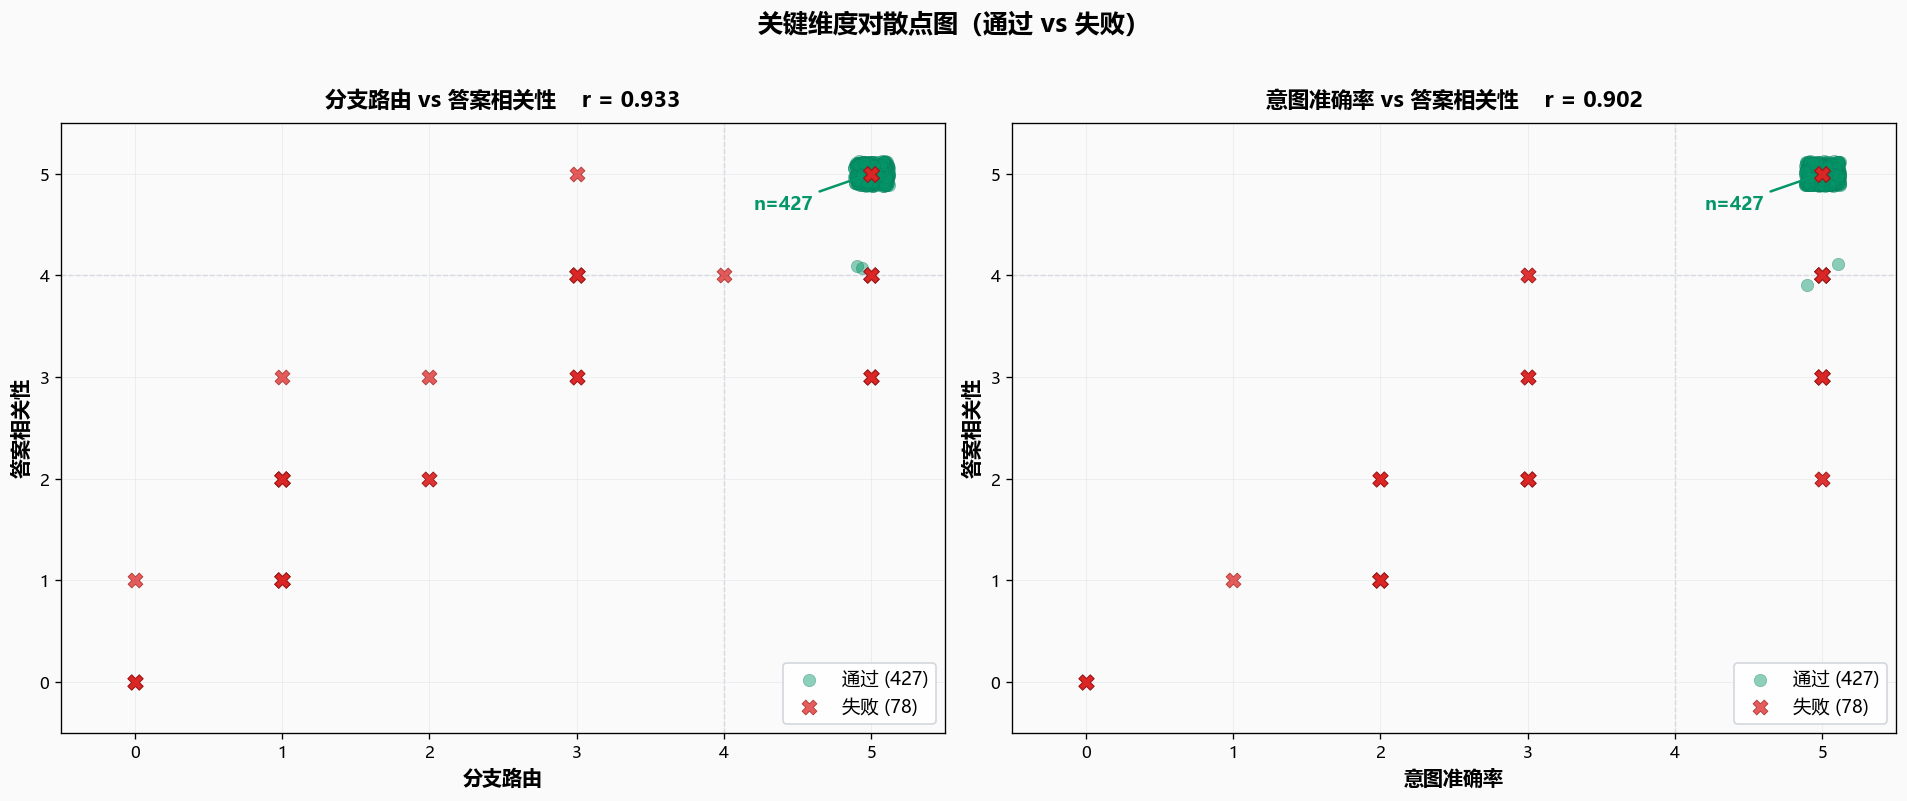

💾 已保存: charts/15_dimension_scatter.png


In [18]:
# ========== 图6：关键维度对散点图（高对比度版） ==========
top_pairs = corr_pairs[:2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
fig.patch.set_facecolor('#FAFAFA')

COLOR_PASS = '#059669'
COLOR_FAIL = '#DC2626'
EDGE_PASS = '#047857'
EDGE_FAIL = '#991B1B'

# 抖动函数：在整数分数上加微小偏移，打散重叠
def add_jitter(arr, jitter_amount=0.12):
    return arr + np.random.uniform(-jitter_amount, jitter_amount, size=len(arr))

for idx, (n1, n2, r) in enumerate(top_pairs):
    ax = axes[idx]
    ax.set_facecolor('#FAFAFA')

    c1 = [k for k, v in SCORE_NAMES_CN.items() if v == n1][0]
    c2 = [k for k, v in SCORE_NAMES_CN.items() if v == n2][0]

    passed = df[df['all_pass']].copy()
    failed = df[~df['all_pass']].copy()

    # --- 通过组：加抖动 + 大点 + 描边 ---
    x_pass = add_jitter(passed[c1].values)
    y_pass = add_jitter(passed[c2].values)
    ax.scatter(x_pass, y_pass,
               s=55, c=COLOR_PASS, alpha=0.45,
               edgecolors=EDGE_PASS, linewidth=0.4,
               marker='o', label=f'通过 ({len(passed)})', zorder=3)

    # --- 失败组：更大更红 + 描边 ---
    ax.scatter(failed[c1], failed[c2],
               s=80, c=COLOR_FAIL, alpha=0.75,
               edgecolors=EDGE_FAIL, linewidth=0.5,
               marker='X', label=f'失败 ({len(failed)})', zorder=4)

    # --- 在 (5,5) 附近标注通过组数量 ---
    ax.annotate(f'n={len(passed)}', xy=(5, 5), xytext=(4.2, 4.65),
                fontsize=11, fontweight='bold', color=COLOR_PASS,
                arrowprops=dict(arrowstyle='->', color=COLOR_PASS, lw=1.5))

    # --- 及格线网格 ---
    ax.axhline(y=4, color='#9CA3AF', linestyle='--', linewidth=0.8, alpha=0.6, zorder=1)
    ax.axvline(x=4, color='#9CA3AF', linestyle='--', linewidth=0.8, alpha=0.6, zorder=1)

    ax.set_xlabel(n1, fontsize=12, fontweight='bold')
    ax.set_ylabel(n2, fontsize=12, fontweight='bold')
    ax.set_title(f'{n1} vs {n2}    r = {r:.3f}',
                 fontsize=13, fontweight='bold', pad=10)

    leg = ax.legend(loc='lower right', fontsize=11, framealpha=0.95,
                    edgecolor='#D1D5DB', fancybox=True)
    leg.get_frame().set_linewidth(1)

    ax.set_xlim(-0.5, 5.5)
    ax.set_ylim(-0.5, 5.5)
    ax.tick_params(labelsize=10)
    ax.grid(True, color='#E5E7EB', linewidth=0.5, alpha=0.8)

plt.suptitle('关键维度对散点图（通过 vs 失败）', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('charts/15_dimension_scatter.png', facecolor=fig.get_facecolor())
plt.show()
print('💾 已保存: charts/15_dimension_scatter.png')

## 3.10 关键发现总结

In [15]:
# ========== 关键发现总结 ==========
print('=' * 70)
print('📋 模块三：相关性分析 — 关键发现')
print('=' * 70)

# 预提取统计值
top_lev_name = lev_df.iloc[0]['dimension_cn']
top_lev_r = lev_df.iloc[0]['correlation']
top_lev_gap = lev_df.iloc[0]['gap']
top_lev_p = lev_df.iloc[0]['p_value']

second_lev_name = lev_df.iloc[1]['dimension_cn'] if len(lev_df) > 1 else 'N/A'
second_lev_r = lev_df.iloc[1]['correlation'] if len(lev_df) > 1 else 0

# 最强/最弱维度对
top_pair = corr_pairs[0] if corr_pairs else ('N/A', 'N/A', 0)

# 最弱维度
desc_stats = df[SCORE_COLS].describe().T
weakest_dim_idx = desc_stats['mean'].idxmin()
weakest_dim_val = desc_stats.loc[weakest_dim_idx, 'mean']
weakest_dim_cn = SCORE_NAMES_CN.get(weakest_dim_idx, weakest_dim_idx)

# 波动最大维度
var_dim_idx = desc_stats['std'].idxmax()
var_dim_val = desc_stats.loc[var_dim_idx, 'std']
var_dim_cn = SCORE_NAMES_CN.get(var_dim_idx, var_dim_idx)

print(f'\n1. 杠杆维度（改善优先级最高）')
print(f'   {top_lev_name}  (r = {top_lev_r:.3f}, p = {top_lev_p:.2e})')
print(f'   通过组 vs 失败组差距: {top_lev_gap:.2f} 分')
print(f'   → 改善该维度对整体通过率提升效果最大')

if len(lev_df) > 1:
    print(f'\n   次杠杆维度: {second_lev_name} (r = {second_lev_r:.3f})')

print(f'\n2. 维度间最强关联')
print(f'   {top_pair[0]} ↔ {top_pair[1]}: r = {top_pair[2]:.3f}')
print(f'   → 两者高度联动，可能受同一系统组件影响')

print(f'\n3. 系统最弱维度')
print(f'   {weakest_dim_cn}  (均值 {weakest_dim_val:.2f})')
print(f'   → 该维度是系统短板，需针对性优化')

print(f'\n4. 波动最大维度')
print(f'   {var_dim_cn}  (标准差 {var_dim_val:.2f})')
print(f'   → 该维度在不同用例间表现不稳定，需固化规则')

print(f'\n5. 根因与维度关联')
for rc in rc_dim.index:
    weakest = rc_dim.loc[rc].idxmin()
    val = rc_dim.loc[rc].min()
    print(f'   {rc:14s} → 最弱维度: {weakest} ({val:.2f})')

print(f'\n6. 难度交互效应（下降最明显的维度）')
if '简单' in diff_dim.index and '困难' in diff_dim.index:
    deltas = {}
    for dim in diff_dim.columns:
        deltas[dim] = diff_dim.loc['困难', dim] - diff_dim.loc['简单', dim]
    sorted_deltas = sorted(deltas.items(), key=lambda x: x[1])
    for dim, delta in sorted_deltas[:3]:
        direction = '↓' if delta < 0 else '↑'
        print(f'   {dim:8s}: 简单 = {diff_dim.loc["简单", dim]:.2f} → 困难 = {diff_dim.loc["困难", dim]:.2f}  ({direction}{abs(delta):.2f})')

print(f'\n7. 优化策略推论')
print(f'   P1: 优化 {top_lev_name} → 杠杆效应最大 (r = {top_lev_r:.3f})')
print(f'   P2: 加固 {weakest_dim_cn} → 补齐系统最短木板 (均值 {weakest_dim_val:.2f})')
print(f'   P3: 稳定 {var_dim_cn} → 降低波动 (σ = {var_dim_val:.2f})')

print(f'\n→ 下一步: 进入模块四（优化方案设计），将分析转化为可执行的修复方案')


📋 模块三：相关性分析 — 关键发现

1. 杠杆维度（改善优先级最高）
   信息完整性  (r = 0.859, p = 2.50e-148)
   通过组 vs 失败组差距: 3.04 分
   → 改善该维度对整体通过率提升效果最大

   次杠杆维度: 答案相关性 (r = 0.747)

2. 维度间最强关联
   分支路由 ↔ 答案相关性: r = 0.933
   → 两者高度联动，可能受同一系统组件影响

3. 系统最弱维度
   信息完整性  (均值 4.32)
   → 该维度是系统短板，需针对性优化

4. 波动最大维度
   信息完整性  (标准差 1.28)
   → 该维度在不同用例间表现不稳定，需固化规则

5. 根因与维度关联
   LLM生成缺陷        → 最弱维度: 信息完整性 (1.83)
   其他/需人工复核       → 最弱维度: 分支路由 (3.00)
   分类器误路由         → 最弱维度: 信息完整性 (0.84)
   幻觉             → 最弱维度: 分支路由 (3.00)

6. 难度交互效应（下降最明显的维度）
   分支路由    : 简单 = 4.91 → 困难 = 4.67  (↓0.24)
   答案相关性   : 简单 = 4.87 → 困难 = 4.71  (↓0.16)
   忠实度     : 简单 = 4.97 → 困难 = 4.83  (↓0.14)

7. 优化策略推论
   P1: 优化 信息完整性 → 杠杆效应最大 (r = 0.859)
   P2: 加固 信息完整性 → 补齐系统最短木板 (均值 4.32)
   P3: 稳定 信息完整性 → 降低波动 (σ = 1.28)

→ 下一步: 进入模块四（优化方案设计），将分析转化为可执行的修复方案


## 3.11 导出分析结果

In [16]:
# ========== 导出 ==========
# 维度相关性矩阵
corr_matrix.to_csv('analysis_output/module3_correlation_matrix.csv', encoding='utf-8-sig')

# 杠杆维度分析
lev_df.to_csv('analysis_output/module3_leverage_dimensions.csv', index=False, encoding='utf-8-sig')

# 根因 × 维度交叉
rc_dim.to_csv('analysis_output/module3_rootcause_dimension.csv', encoding='utf-8-sig')

# 分支 × 维度交叉
branch_display.to_csv('analysis_output/module3_branch_dimension.csv', encoding='utf-8-sig')

# 难度 × 维度交叉
diff_dim.to_csv('analysis_output/module3_difficulty_dimension.csv', encoding='utf-8-sig')

print('✅ 模块三导出完成')
print(f'   - module3_correlation_matrix.csv    (维度相关性矩阵)')
print(f'   - module3_leverage_dimensions.csv   (杠杆维度分析)')
print(f'   - module3_rootcause_dimension.csv   (根因 × 维度交叉)')
print(f'   - module3_branch_dimension.csv     (分支 × 维度交叉)')
print(f'   - module3_difficulty_dimension.csv  (难度 × 维度交叉)')
print(f'   - charts/10-15*.png                 (6 张可视化图表)')


✅ 模块三导出完成
   - module3_correlation_matrix.csv    (维度相关性矩阵)
   - module3_leverage_dimensions.csv   (杠杆维度分析)
   - module3_rootcause_dimension.csv   (根因 × 维度交叉)
   - module3_branch_dimension.csv     (分支 × 维度交叉)
   - module3_difficulty_dimension.csv  (难度 × 维度交叉)
   - charts/10-15*.png                 (6 张可视化图表)
